# TP3.3 — Guided Exercise: Training a Conditional Diffusion Model (CDM)

**Introduction to Deep Generative Models **

For each practical exercise (TP), please work in groups of two or three. Then, create a **private GitHub repository** and add me (my GitHub is **arthur-75**) to your project.

> This notebook transcribes the original PDF. Unfinished `xxx` placeholders and the original starter code have been retained. Use the previous DDPM exercises for the reused components.

This exercise extends the previous DDPM setup to include context-based training, allowing the model to generate samples conditioned on additional information, such as class labels or attributes. You will understand and implement Conditional Denoising Diffusion Models (CDDM).

## 1. Understanding Conditional Diffusion Models (CDM)

A Conditional Diffusion Model (CDM) extends DDPM by conditioning the model on additional information (e.g., class labels, textual descriptions, or other structured data). This enables controlled generation, where outputs are guided by specific attributes.

The denoising step in a conditional model is:

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t,c)\right)+\sigma_t z$$

Where:
- `c` is contextual information (e.g., class labels).
- The model learns to remove noise conditioned on `c`.
- During training, a context-masking strategy is used, randomly ignoring context to ensure robustness.

## 2. Setup: Keeping the Same Components

For this exercise, we reuse the exact setup from the previous DDPM, ensuring consistency.

**Reused Components**

- Packages: Same PyTorch and utility imports.
- Network Hyperparameters: (e.g., feature dimensions, image size).
- Diffusion Hyperparameters: (e.g., number of timesteps, noise schedule).
- Training Hyperparameters: Learning rate, epochs, and batch size.
- DDPM Noise Schedule: Predefined beta schedule.
- Context U-Net Model: Supports conditional input.
- Denoising Function: `denoise_add_noise` remains the same.
- Dataset Handling: Uses `CustomDataset`.
- Perturbation Function: `perturb_input` remains unchanged.

*Use your setup from TP3.1 and TP3.2 before running the code below.*

In [ ]:
# get the course files from the Drive "cours 4 DM" (gdown is already installed on Colab)
# or upload them by hand: diffusion_utilities.py, the models/ folder and the data/ folder
import os
import gdown

if not os.path.exists("diffusion_utilities.py"):
    gdown.download(id="1xN0YQfdAdYjF2mpAftCpBBYfxMdwgjpN", output="diffusion_utilities.py")
if not os.path.exists("models"):
    gdown.download_folder(id="1u9Xl23P1C8TNKa6SZxnx4XS6BaurwVoX", output="models")
print(os.listdir("models"))
if not os.path.exists("data"):
    gdown.download_folder(id="1cCSrrZeoJ6f5lMTqaqV75Avl2uoYsGCR", output="data")
print(os.listdir("data"))

Downloading...
From (original): https://drive.google.com/uc?id=1xN0YQfdAdYjF2mpAftCpBBYfxMdwgjpN
From (redirected): https://drive.google.com/uc?id=1xN0YQfdAdYjF2mpAftCpBBYfxMdwgjpN&confirm=t&uuid=3839c5d8-a1c1-4f3d-93a3-8bc857afd92a
To: /content/diffusion_utilities.py
100%|██████████| 9.93k/9.93k [00:00<00:00, 24.6MB/s]
Retrieving folder contents


Processing file 1RncKsQi1mmrktyo6c9jLWELW586VJf9U context_model_0.pth
Processing file 1OtOHPYEIeu3-CEhnY15ZZDifMd44C8zv context_model_4.pth
Processing file 1ySVxtx4sK4EMAIZ0cddXHzR9hA6RK4oB context_model_8.pth
Processing file 1bRl2n232PxmZkWdiniTCtWT668fGd005 context_model_12.pth
Processing file 1wbdzTWVTQeUo2mK9H3Ip_nSFRpfnSMhO context_model_16.pth
Processing file 1obwI64lar7q_TiO9LqPVIEEc4NkSBuuz context_model_20.pth
Processing file 1s47l76eoYovZsl3P_qLK2D5qTXEaDJFa context_model_24.pth
Processing file 1HtvZ6VkfaCkSizjVqs69j53WVaKhe6s6 context_model_28.pth
Processing file 1qYpKkZk6mt1r-uXNglfOixPZLoey5if_ context_model_31.pth
Processing file 1QfhraKeTtOTAIBjCExA4zWUPMf55H9z8 context_model_trained.pth
Processing file 1miK3sxBOdOUlvi25NEW-tYnnJruhB1P4 model_0.pth
Processing file 1rF907kKhk25QVt_hVuhTcFG26GeA8Fg2 model_4.pth
Processing file 1XHXFOr29JvEL4cBYoIUWqr2gtVA5cqYP model_8.pth
Processing file 1pnf1bm7t4ouaPIP6zqAxFhdb-38aRKwJ model_12.pth
Processing file 1Tsv8Gq2Zhr9ruC3yhnNnkS

Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1RncKsQi1mmrktyo6c9jLWELW586VJf9U
To: /content/models/context_model_0.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 57.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=1OtOHPYEIeu3-CEhnY15ZZDifMd44C8zv
To: /content/models/context_model_4.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 39.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=1ySVxtx4sK4EMAIZ0cddXHzR9hA6RK4oB
To: /content/models/context_model_8.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 57.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1bRl2n232PxmZkWdiniTCtWT668fGd005
To: /content/models/context_model_12.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 97.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1wbdzTWVTQeUo2mK9H3Ip_nSFRpfnSMhO
To: /content/models/context_model_16.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 62.1MB/s

['context_model_31.pth', 'context_model_4.pth', 'context_model_20.pth', 'context_model_0.pth', 'context_model_8.pth', 'model_20.pth', 'model_16.pth', 'model_8.pth', 'model_28.pth', 'model_31.pth', 'model_24.pth', 'context_model_12.pth', 'model_4.pth', 'context_model_16.pth', 'context_model_24.pth', 'model_trained.pth', 'context_model_trained.pth', 'context_model_28.pth', 'model_12.pth', 'model_0.pth']
Processing file 1qyCRbJNrQQXShIpLon-wV2sX_LKLVm85 sprite_labels_nc_1788_16x16.npy
Processing file 18tNPeb99H4W6uzlntgPn4oLD80jnLLDP sprites_1788_16x16.npy


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1qyCRbJNrQQXShIpLon-wV2sX_LKLVm85
To: /content/data/sprite_labels_nc_1788_16x16.npy
100%|██████████| 3.58M/3.58M [00:00<00:00, 246MB/s]
Downloading...
From: https://drive.google.com/uc?id=18tNPeb99H4W6uzlntgPn4oLD80jnLLDP
To: /content/data/sprites_1788_16x16.npy
100%|██████████| 68.7M/68.7M [00:00<00:00, 96.8MB/s]

['sprites_1788_16x16.npy', 'sprite_labels_nc_1788_16x16.npy']



Download completed


In [ ]:
# setup from TP3.1 and TP3.2
from tqdm import tqdm
import torch
import os
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from diffusion_utilities import ResidualConvBlock, UnetUp, UnetDown, EmbedFC, plot_sample, CustomDataset, transform

# training hyperparameters
batch_size = 100
n_epoch = 2
lrate = 1e-3

# diffusion hyperparameters
timesteps = 500
beta1 = 1e-4
beta2 = 0.02

# network hyperparameters
device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
n_feat = 64  # 64 hidden dimension feature
n_cfeat = 5  # context vector is of size 5
height = 16  # 16x16 image
save_dir = './weights/'  # our checkpoints (the teacher's ones are in ./models/)

# construct DDPM noise schedule
b_t = beta1 + ((beta2 - beta1) * torch.linspace(0, 1, timesteps + 1, device=device))
a_t = 1 - b_t
ab_t = torch.cumsum(a_t.log(), dim=0).exp()
ab_t[0] = 1


class ContextUnet(nn.Module):
    def __init__(self, in_channels, n_feat=256, n_cfeat=10, height=28):  # cfeat - context features
        super(ContextUnet, self).__init__()

        # number of input channels, number of intermediate feature maps and number of classes
        self.in_channels = in_channels
        self.n_feat = n_feat
        self.n_cfeat = n_cfeat
        self.h = height  # assume h == w. must be divisible by 4, so 28,24,20,16...

        # Initialize the initial convolutional layer
        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        # Initialize the down-sampling path of the U-Net with two levels
        self.down1 = UnetDown(n_feat, n_feat)        # down1 #[10, 256, 8, 8]
        self.down2 = UnetDown(n_feat, 2 * n_feat)    # down2 #[10, 256, 4, 4]

        # original: self.to_vec = nn.Sequential(nn.AvgPool2d(7), nn.GELU())
        self.to_vec = nn.Sequential(nn.AvgPool2d((4)), nn.GELU())

        # Embed the timestep and context labels with a one-layer fully connected neural network
        self.timeembed1 = EmbedFC(1, 2*n_feat)
        self.timeembed2 = EmbedFC(1, 1*n_feat)
        self.contextembed1 = EmbedFC(n_cfeat, 2*n_feat)
        self.contextembed2 = EmbedFC(n_cfeat, 1*n_feat)

        # Initialize the up-sampling path of the U-Net with three levels
        self.up0 = nn.Sequential(
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, self.h//4, self.h//4),  # up-sample
            nn.GroupNorm(8, 2 * n_feat),  # normalize
            nn.ReLU(),
        )
        self.up1 = UnetUp(4 * n_feat, n_feat)
        self.up2 = UnetUp(2 * n_feat, n_feat)

        # Initialize the final convolutional layers to map to same number of channels as input
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, 3, 1, 1),  # reduce number of feature maps
            nn.GroupNorm(8, n_feat),  # normalize
            nn.ReLU(),
            nn.Conv2d(n_feat, self.in_channels, 3, 1, 1),  # map to same number of channels as input
        )

    def forward(self, x, t, c=None):
        """
        x : (batch, n_feat, h, w) : input image
        t : (batch, n_cfeat) : time step
        c : (batch, n_classes) : context label
        """
        # x is the input image, c is the context label, t is the timestep,
        # context_mask says which samples to block the context on
        x = self.init_conv(x)
        down1 = self.down1(x)          #[10, 256, 8, 8]
        down2 = self.down2(down1)      #[10, 256, 4, 4]
        hiddenvec = self.to_vec(down2)

        # mask out context if context_mask == 1
        if c is None:
            c = torch.zeros(x.shape[0], self.n_cfeat).to(x)

        # embed context and timestep
        cemb1 = self.contextembed1(c).view(-1, self.n_feat * 2, 1, 1)
        temb1 = self.timeembed1(t).view(-1, self.n_feat * 2, 1, 1)
        cemb2 = self.contextembed2(c).view(-1, self.n_feat, 1, 1)
        temb2 = self.timeembed2(t).view(-1, self.n_feat, 1, 1)

        up1 = self.up0(hiddenvec)
        up2 = self.up1(cemb1*up1 + temb1, down2)
        up3 = self.up2(cemb2*up2 + temb2, down1)
        out = self.out(torch.cat((up3, x), 1))
        return out


nn_model = ContextUnet(in_channels=3, n_feat=n_feat, n_cfeat=n_cfeat, height=height).to(device)


# helper function; removes the predicted noise (but adds some noise back in to avoid collapse)
def denoise_add_noise(x, t, pred_noise, z=None):
    if z is None:
        z = torch.randn_like(x)
    noise = b_t.sqrt()[t] * z
    mean = (x - pred_noise * ((1 - a_t[t]) / (1 - ab_t[t]).sqrt())) / a_t[t].sqrt()
    return mean + noise


# helper function: perturbs an image to a specified noise level
def perturb_input(x, t, noise):
    return ab_t.sqrt()[t, None, None, None] * x + (1 - ab_t[t, None, None, None]) * noise


# define sampling function for DDIM
# removes the noise using ddim
def denoise_ddim(x, t, t_prev, pred_noise):
   ab = ab_t[t]
   ab_prev = ab_t[t_prev]

   x0_pred = ab_prev.sqrt() / ab.sqrt() * (x - (1 - ab).sqrt() * pred_noise)
   dir_xt = (1 - ab_prev).sqrt() * pred_noise

   return x0_pred + dir_xt


# dataset with the labels this time (null_context=False) and optimizer
dataset = CustomDataset("./data/sprites_1788_16x16.npy",
                        "./data/sprite_labels_nc_1788_16x16.npy", transform, null_context=False)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=1)
optim = torch.optim.Adam(nn_model.parameters(), lr=lrate)

sprite shape: (89400, 16, 16, 3)
labels shape: (89400, 5)


## 3. Training a Conditional Diffusion Model

- Incorporating Context (`c`) into Training
- Randomly Masking Context (to prevent over-reliance)
- Updating the Loss Function (same as DDPM but conditioned on context)

**Implementation Steps**

1. Enable Training Mode.
2. Decay Learning Rate Linearly Over Epochs.
3. Loop Through Batches: extract images (`x`) and context (`c`), and convert them to the correct device (GPU/CPU).
4. Randomly Mask Out Context: apply Bernoulli masking to randomly nullify `c` with 90% probability (as described in the source).
5. Apply Noise to Input Images (`perturb_input`).
6. Train the U-Net to Predict Noise Given Context.
7. Compute Mean Squared Error Loss and Update Weights.
8. Save Model Periodically.

In [ ]:
# training with context code
# set into train mode
nn_model.train()

for ep in range(n_epoch):
    print(f'epoch {ep}')

    # linearly decay learning rate
    optim.param_groups[0]['lr'] = lrate*(1-ep/n_epoch)

    pbar = tqdm(dataloader, mininterval=2 )
    for x, c in pbar:   # x: images  c: context
        optim.zero_grad()
        x = x.to(device)
        c = c.to(x)

        # randomly mask out c
        context_mask = torch.bernoulli(torch.zeros(c.shape[0]) + 0.9).to(device)
        c = c * context_mask.unsqueeze(-1)

        # perturb data
        noise = torch.randn_like(x)
        t = torch.randint(1, timesteps + 1, (x.shape[0],)).to(device)
        x_pert = perturb_input(x, t, noise)

        # use network to recover noise
        pred_noise = nn_model(x_pert, t / timesteps, c=c)

        # loss is mean squared error between the predicted and true noise
        loss = F.mse_loss(pred_noise, noise)
        loss.backward()
        optim.step()

    # save model periodically
    if ep%4==0 or ep == int(n_epoch-1):
        if not os.path.exists(save_dir):
            os.mkdir(save_dir)
        torch.save(nn_model.state_dict(), save_dir + f"context_model_{ep}.pth")
        print('saved model at ' + save_dir + f"context_model_{ep}.pth")

epoch 0


100%|██████████| 894/894 [00:29<00:00, 30.04it/s]


saved model at ./weights/context_model_0.pth
epoch 1


100%|██████████| 894/894 [00:28<00:00, 31.92it/s]

saved model at ./weights/context_model_1.pth


## 4. Sampling with Context

After training, we generate context-conditioned samples.

1. Load Pretrained Model and Set to Evaluation Mode.
2. Sample noise $x_T \sim \mathcal{N}(0,I)$.
3. Iteratively Remove Noise, Conditioned on Context.
4. Generate Samples and Visualize Them.

In [ ]:
# load the trained context model given by the teacher
nn_model.load_state_dict(torch.load("./models/context_model_trained.pth", map_location=device))
nn_model.eval()
print("Loaded in Context Model")

Loaded in Context Model


In [ ]:
# sample with context using standard algorithm
@torch.no_grad()
def sample_ddpm_context(n_sample, context, save_rate=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)

    # array to keep track of generated steps for plotting
    intermediate = []
    for i in range(timesteps, 0, -1):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        # sample some random noise to inject back in. For i = 1, don't add back in noise
        z = torch.randn_like(samples) if i > 1 else 0

        eps = nn_model(samples, t, c=context)    # predict noise e_(x_t,t, ctx)
        samples = denoise_add_noise(samples, i, eps, z)
        if i % save_rate==0 or i==timesteps or i<8:
            intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

## 5. Visualizing Context-Conditioned Samples

### Random Context Selection

In [ ]:
plt.clf()
ctx = F.one_hot(torch.randint(0, 5, (32,)), 5).to(device=device).float()
samples, intermediate = sample_ddpm_context(32, ctx)
animation_ddpm_context = plot_sample(intermediate, 32, 4, save_dir, "ani_run", None, save=False)
HTML(animation_ddpm_context.to_jshtml())

<Figure size 640x480 with 0 Axes>

### Custom Context (User Defined)

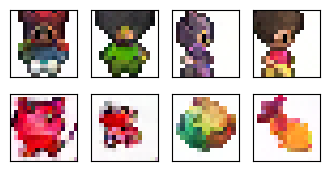

In [ ]:
def show_images(imgs, nrow=2):
    _, axs = plt.subplots(nrow, imgs.shape[0] // nrow, figsize=(4,2 ))
    axs = axs.flatten()
    for img, ax in zip(imgs, axs):
        img = (img.permute(1, 2, 0).clone().clip(-1, 1).detach().cpu().numpy() +1) / 2
        ax.set_xticks([])
        ax.set_yticks([])
        ax.imshow(img)
    plt.show()

ctx = torch.tensor([
    [1,0,0,0,0],  # Hero
    [1,0,0,0,0],
    [0,0,0,0,1],  # Side-facing
    [0,0,0,0,1],
    [0,1,0,0,0],  # Non-hero
    [0,1,0,0,0],
    [0,0,1,0,0],  # Food
    [0,0,1,0,0],
]).float().to(device)
samples, _ = sample_ddpm_context(ctx.shape[0], ctx)
show_images(samples)

### Blending Multiple Contexts

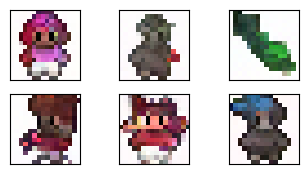

In [ ]:
ctx = torch.tensor([
    [1,0,0,0,0],  # Human
    [1,0,0.6,0,0],
    [0,0,0.6,0.4,0],
    [1,0,0,0,1],
    [1,1,0,0,0],
    [1,0,0,1,0]
]).float().to(device)
samples, _ = sample_ddpm_context(ctx.shape[0], ctx)
show_images(samples)

## 4. DDIM with Context

Use the same `denoise_ddim` to plot.

*Section numbering retained from the original document.*

In [ ]:
# fast sampling algorithm with context
@torch.no_grad()
def sample_ddim_context(n_sample, context, n=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)

    # array to keep track of generated steps for plotting
    intermediate = []
    step_size = timesteps // n
    for i in range(timesteps, 0, -step_size):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        eps = nn_model(samples, t, c=context)    # predict noise e_(x_t,t)
        samples = denoise_ddim(samples, i, i - step_size, eps)
        intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

# visualize samples
plt.clf()
ctx = F.one_hot(torch.randint(0, 5, (32,)), 5).to(device=device).float()
samples, intermediate = sample_ddim_context(32, ctx)
animation_ddpm_context = plot_sample(intermediate,32,4,save_dir, "ani_run", None, save=False)
HTML(animation_ddpm_context.to_jshtml())

<Figure size 640x480 with 0 Axes>

## Questions

1. Write the DDPM and DDIM equations and how do they work?
2. What is the difference between DDPM and DDIM? What is the advantage of each?

**Your answers:**

**1. Equations**

Both use the same trained network $\epsilon_\theta$ (trained with $\|\epsilon-\epsilon_\theta(x_t,t)\|^2$ where $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$). Only the sampling changes.

*DDPM:* we start from $x_T\sim\mathcal N(0,I)$ and for $t=T,\dots,1$:

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\right)+\sqrt{\beta_t}\,z,\qquad z\sim\mathcal N(0,I)$$

At each step we remove a little bit of the predicted noise and add back some new random noise. We have to do all the $T=500$ steps.

*DDIM:* we first estimate the clean image, then go directly to an earlier step $t'$ (here $t'=t-\text{step\_size}$):

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},\qquad x_{t'}=\sqrt{\bar\alpha_{t'}}\,\hat x_0+\sqrt{1-\bar\alpha_{t'}}\,\epsilon_\theta(x_t,t)$$

There is no random $z$, so the process is deterministic and we can skip steps (20 steps instead of 500 in this notebook). For the conditional model we just use $\epsilon_\theta(x_t,t,c)$ in both.

**2. Difference and advantages**

- DDPM is stochastic and needs every step: it is slow, but the samples are good and diverse.
- DDIM is deterministic (same $x_T$ gives the same image) and can skip steps, so it is much faster and it does not need a new training. With very few steps the quality can be a bit lower.